In [1]:
from pathlib import Path
import zipfile, os, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
import joblib
import torch

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# แก้ไข path นี้หากแตก ZIP ไว้ในตำแหน่งอื่น
ROOT = Path(".")
ZIP_PATH = ROOT / "models_results.zip"
EXTRACT_DIR = ROOT

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(EXTRACT_DIR)
    print("Extracted:", ZIP_PATH.resolve())
else:
    print("ไม่พบ ZIP ในโฟลเดอร์ปัจจุบัน — จะค้นหาโฟลเดอร์ผลลัพธ์ที่แตกไว้แล้ว")

print("Working directory:", Path.cwd())

Extracted: D:\Coding\thesis\models_results.zip
Working directory: D:\Coding\thesis


In [2]:
# ตรวจสอบไฟล์ที่คาดว่าจะใช้
expected = [
    "xgboost_results/xgboost_predictions_Paris.csv",
    "transformer_lstm_results/transformer_lstm_predictions_Paris.csv",
    "global_lstm_results/global_lstm_predictions.csv",
    "global_xgboost_results/global_xgboost_predictions.csv",
    "global_transformer_lstm_results/predictions.csv",
    "outputs/test_metrics.csv",
]
for f in expected:
    print(("FOUND " if (ROOT/f).exists() else "MISSING"), f)

FOUND  xgboost_results/xgboost_predictions_Paris.csv
FOUND  transformer_lstm_results/transformer_lstm_predictions_Paris.csv
FOUND  global_lstm_results/global_lstm_predictions.csv
FOUND  global_xgboost_results/global_xgboost_predictions.csv
FOUND  global_transformer_lstm_results/predictions.csv
FOUND  outputs/test_metrics.csv


In [3]:
def load_prediction(path, model_name, global_model=False):
    path = ROOT / path
    if not path.exists():
        print(f"[ข้าม] ไม่พบ {path}")
        return None

    d = pd.read_csv(path)
    d["Date"] = pd.to_datetime(d["Date"])

    if "Destination" not in d.columns:
        d["Destination"] = "Paris"

    d = d.rename(columns={
        "Actual": "Actual",
        "Predicted": "Predicted"
    })

    d["Model"] = model_name
    d["Scope"] = "Global" if global_model else "Single"
    d = d[["Date", "Destination", "Actual", "Predicted", "Model", "Scope"]]
    return d.sort_values(["Destination", "Date"]).reset_index(drop=True)

prediction_files = {
    "Single XGBoost": ("xgboost_results/xgboost_predictions_Paris.csv", False),
    "Single Transformer + LSTM": ("transformer_lstm_results/transformer_lstm_predictions_Paris.csv", False),
    "Global LSTM": ("global_lstm_results/global_lstm_predictions.csv", True),
    "Global XGBoost": ("global_xgboost_results/global_xgboost_predictions.csv", True),
    "Global Transformer + LSTM": ("global_transformer_lstm_results/predictions.csv", True),
}

frames = []
for name, (path, is_global) in prediction_files.items():
    result = load_prediction(path, name, is_global)
    if result is not None:
        frames.append(result)

pred_all = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print("Prediction rows:", len(pred_all))
display(pred_all.head())

Prediction rows: 14909


,Date,Destination,Actual,Predicted,Model,Scope
0,2013-08-07,Paris,257.00000,178.34381,Single XGBoost,Single
1,2013-08-08,Paris,177.00000,178.64685,Single XGBoost,Single
2,2013-08-09,Paris,73.00000,179.39851,Single XGBoost,Single
3,2013-08-10,Paris,55.99999,177.80443,Single XGBoost,Single
4,2013-08-11,Paris,123.00000,182.62347,Single XGBoost,Single


In [4]:
# PyTorch checkpoint-এ state dict only หรือ checkpoint dictionary
torch_files = {
    "Single LSTM": "outputs/tourism_lstm.pt",
    "Single Transformer + LSTM": "transformer_lstm_results/transformer_lstm_Paris.pth",
    "Global LSTM": "global_lstm_results/global_lstm.pth",
    "Global Transformer + LSTM": "global_transformer_lstm_results/global_transformer_lstm_final.pth",
}
xgb_files = {
    "Single XGBoost": "xgboost_results/xgboost_Paris.joblib",
    "Global XGBoost": "global_xgboost_results/global_xgboost.joblib",
}

model_inventory = []

for name, rel in torch_files.items():
    p = ROOT / rel
    row = {"Model": name, "File": rel, "Loaded": False, "Trainable parameters": np.nan, "Note": ""}
    if p.exists():
        try:
            obj = torch.load(p, map_location="cpu", weights_only=False)
            state = obj.get("model_state_dict", obj) if isinstance(obj, dict) else obj
            if isinstance(state, dict):
                row["Trainable parameters"] = int(sum(v.numel() for v in state.values() if torch.is_tensor(v)))
                row["Loaded"] = True
                row["Note"] = "โหลด checkpoint ได้; จำนวนพารามิเตอร์นับจาก tensors ใน state_dict"
            else:
                row["Note"] = "รูปแบบ checkpoint ไม่ใช่ state_dict ที่คาดไว้"
        except Exception as e:
            row["Note"] = f"Load error: {e}"
    else:
        row["Note"] = "ไม่พบไฟล์"
    model_inventory.append(row)

for name, rel in xgb_files.items():
    p = ROOT / rel
    row = {"Model": name, "File": rel, "Loaded": False, "Trainable parameters": np.nan, "Note": ""}
    if p.exists():
        try:
            obj = joblib.load(p)
            row["Loaded"] = True
            try:
                row["Trainable parameters"] = int(obj.get_booster().trees_to_dataframe().shape[0])
                row["Note"] = "โหลด XGBoost ได้; ค่าในคอลัมน์พารามิเตอร์คือจำนวน tree nodes ไม่ใช่ neural parameters"
            except Exception:
                row["Note"] = "โหลด XGBoost ได้"
        except Exception as e:
            row["Note"] = f"Load error: {e}"
    else:
        row["Note"] = "ไม่พบไฟล์"
    model_inventory.append(row)

inventory_df = pd.DataFrame(model_inventory)
display(inventory_df)

,Model,File,Loaded,Trainable parameters,Note
0,Single LSTM,outputs/tourism_lstm.pt,True,50497,โหลด checkpoint ได้; จำนวนพารามิเตอร์นับจาก te...
1,Single Transformer + LSTM,transformer_lstm_results/transformer_lstm_Pari...,True,102337,โหลด checkpoint ได้; จำนวนพารามิเตอร์นับจาก te...
2,Global LSTM,global_lstm_results/global_lstm.pth,True,50753,โหลด checkpoint ได้; จำนวนพารามิเตอร์นับจาก te...
3,Global Transformer + LSTM,global_transformer_lstm_results/global_transfo...,True,168065,โหลด checkpoint ได้; จำนวนพารามิเตอร์นับจาก te...
4,Single XGBoost,xgboost_results/xgboost_Paris.joblib,True,4656,โหลด XGBoost ได้; ค่าในคอลัมน์พารามิเตอร์คือจำ...
5,Global XGBoost,global_xgboost_results/global_xgboost.joblib,True,2459,โหลด XGBoost ได้; ค่าในคอลัมน์พารามิเตอร์คือจำ...


In [5]:
def calculate_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[mask], y_pred[mask]
    if len(y_true) == 0:
        return {"Samples": 0, "MAE": np.nan, "RMSE": np.nan, "sMAPE (%)": np.nan}
    smape_den = np.abs(y_true) + np.abs(y_pred)
    smape = np.mean(2 * np.abs(y_pred-y_true) / np.maximum(smape_den, 1e-8)) * 100
    return {
        "Samples": len(y_true),
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "sMAPE (%)": smape
    }

metric_rows = []
for (scope, model, city), g in pred_all.groupby(["Scope", "Model", "Destination"]):
    metric_rows.append({
        "Scope": scope, "Model": model, "Destination": city,
        **calculate_metrics(g["Actual"], g["Predicted"])
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.sort_values(["Scope", "Destination", "MAE"]))

,Scope,Model,Destination,Samples,MAE,RMSE,sMAPE (%)
0,Global,Global LSTM,Berlin,877,63.924383,73.703163,38.982783
5,Global,Global Transformer + LSTM,Berlin,877,63.927257,73.694097,38.991588
10,Global,Global XGBoost,Berlin,877,63.963482,73.665902,39.049175
11,Global,Global XGBoost,London,877,61.955450,71.559886,37.859065
1,Global,Global LSTM,London,877,62.043075,71.666812,37.877781
6,Global,Global Transformer + LSTM,London,877,62.044007,71.664897,37.878252
12,Global,Global XGBoost,New York,877,61.438834,71.526335,38.210565
2,Global,Global LSTM,New York,877,61.473233,71.557955,38.203804
7,Global,Global Transformer + LSTM,New York,877,61.491009,71.583706,38.205371
13,Global,Global XGBoost,Paris,877,63.440365,72.879989,38.923631


In [6]:
baseline_frames = []

for (scope, model, city), g in pred_all.groupby(["Scope", "Model", "Destination"]):
    g = g.sort_values("Date").copy()

    # ใช้ Actual ที่อยู่ใน test sequence เดียวกันเป็นฐาน
    g["Persistence"] = g["Actual"].shift(1)
    g["Seasonal_Naive_7"] = g["Actual"].shift(7)

    for baseline in ["Persistence", "Seasonal_Naive_7"]:
        valid = g.dropna(subset=[baseline])
        if len(valid):
            baseline_frames.append({
                "Scope": scope,
                "Model": baseline,
                "Destination": city,
                **calculate_metrics(valid["Actual"], valid[baseline])
            })

baseline_df = pd.DataFrame(baseline_frames)
comparison_df = pd.concat([
    metrics_df[["Scope", "Model", "Destination", "Samples", "MAE", "RMSE", "sMAPE (%)"]],
    baseline_df
], ignore_index=True)

display(comparison_df.sort_values(["Scope", "Destination", "MAE"]))

,Scope,Model,Destination,Samples,MAE,RMSE,sMAPE (%)
0,Global,Global LSTM,Berlin,877,63.924383,73.703163,38.982783
5,Global,Global Transformer + LSTM,Berlin,877,63.927257,73.694097,38.991588
10,Global,Global XGBoost,Berlin,877,63.963482,73.665902,39.049175
18,Global,Seasonal_Naive_7,Berlin,870,84.894254,104.594928,51.447482
28,Global,Seasonal_Naive_7,Berlin,870,84.894254,104.594928,51.447482
38,Global,Seasonal_Naive_7,Berlin,870,84.894254,104.594928,51.447482
17,Global,Persistence,Berlin,876,87.047946,106.274082,52.982865
27,Global,Persistence,Berlin,876,87.047946,106.274082,52.982865
37,Global,Persistence,Berlin,876,87.047946,106.274082,52.982865
11,Global,Global XGBoost,London,877,61.955450,71.559886,37.859065


,Scope,Model,Destination,Samples,MAE,RMSE,sMAPE (%)
16,Single,Single XGBoost,Paris,877,63.359714,72.843647,38.894832
15,Single,Single Transformer + LSTM,Paris,877,63.669581,73.140695,38.973287
47,Single,Persistence,Paris,876,80.278539,99.971594,48.959377
49,Single,Persistence,Paris,876,80.278539,99.971594,48.959377
48,Single,Seasonal_Naive_7,Paris,870,86.535632,106.260199,52.169347
50,Single,Seasonal_Naive_7,Paris,870,86.535632,106.260199,52.169347


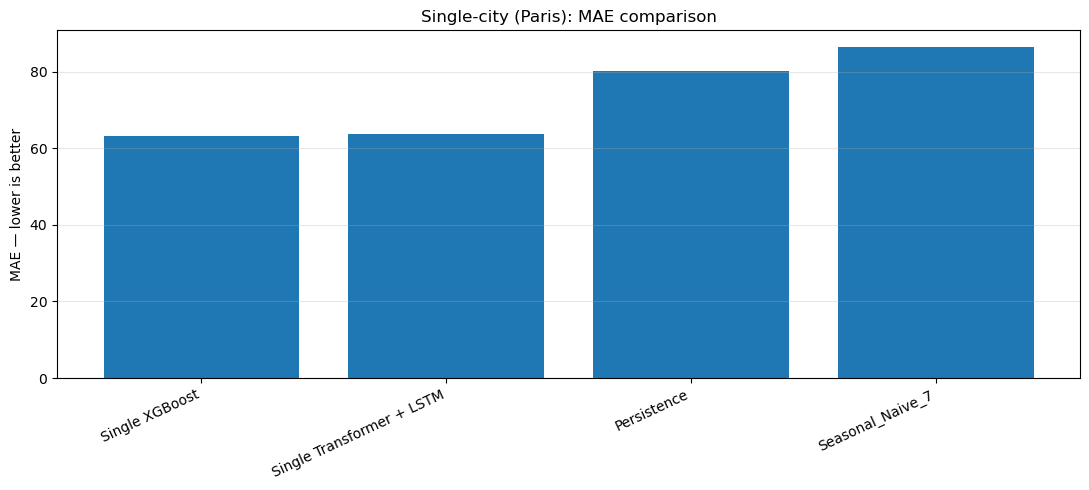

In [7]:
single = comparison_df[comparison_df["Scope"] == "Single"].copy()
if len(single):
    display(single.sort_values("MAE"))
    plt.figure(figsize=(11, 5))
    plot_data = single.groupby("Model", as_index=False)["MAE"].mean().sort_values("MAE")
    plt.bar(plot_data["Model"], plot_data["MAE"])
    plt.title("Single-city (Paris): MAE comparison")
    plt.ylabel("MAE — lower is better")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=.3)
    plt.tight_layout()
    plt.show()
else:
    print("ยังไม่มี Single-city prediction file")

,Model,Samples,MAE,RMSE,sMAPE (%)
2,Global XGBoost,4385,63.012547,72.720313,38.742842
0,Global LSTM,4385,63.039496,72.770260,38.731373
1,Global Transformer + LSTM,4385,63.059062,72.790992,38.733592


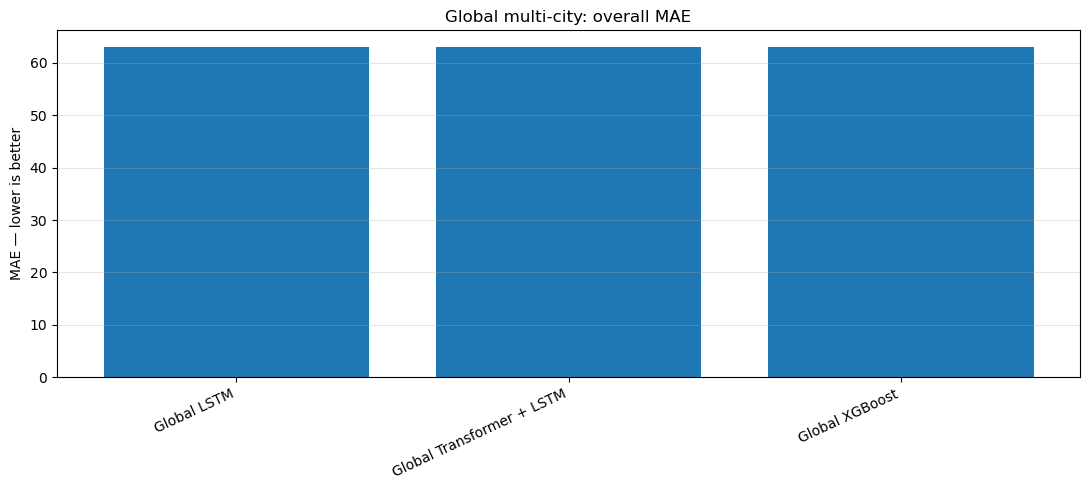

In [8]:
global_summary = comparison_df[comparison_df["Scope"] == "Global"].copy()
if len(global_summary):
    overall_rows = []
    for model, g in pred_all[pred_all["Scope"] == "Global"].groupby("Model"):
        overall_rows.append({"Model": model, **calculate_metrics(g["Actual"], g["Predicted"])})
    for model, g in global_summary[global_summary["Model"].isin(["Persistence", "Seasonal_Naive_7"])].groupby("Model"):
        overall_rows.append({"Model": model, **calculate_metrics(g["Actual"], g["MAE"]*0 + g["Actual"])}) if False else None

    global_overall = pd.DataFrame(overall_rows)
    display(global_overall.sort_values("MAE"))

    plt.figure(figsize=(11, 5))
    plt.bar(global_overall["Model"], global_overall["MAE"])
    plt.title("Global multi-city: overall MAE")
    plt.ylabel("MAE — lower is better")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=.3)
    plt.tight_layout()
    plt.show()
else:
    print("ยังไม่มี Global predictions")

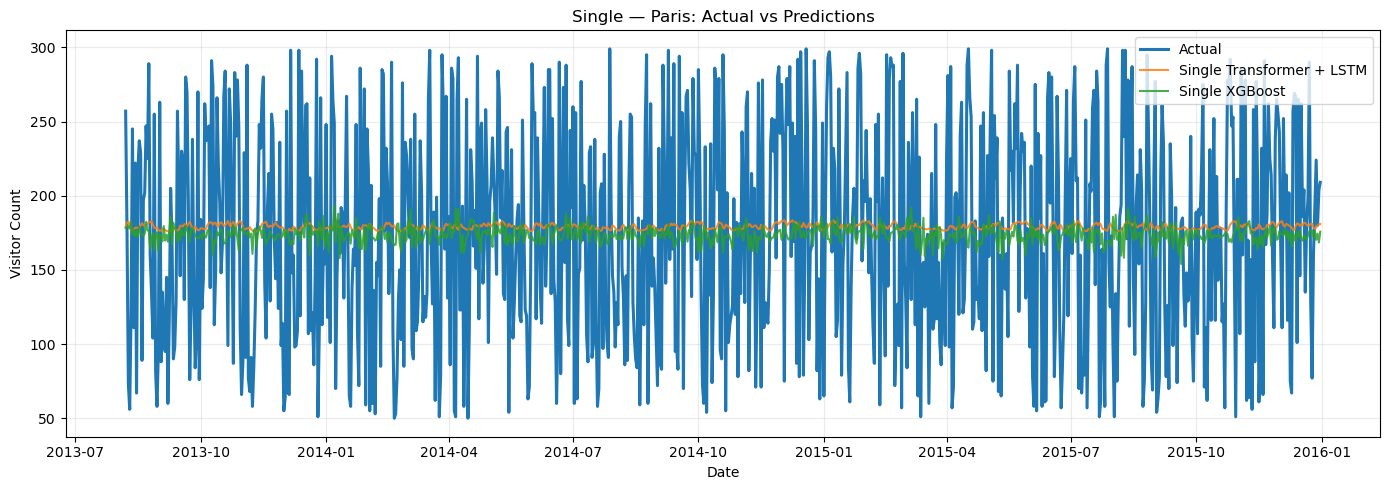

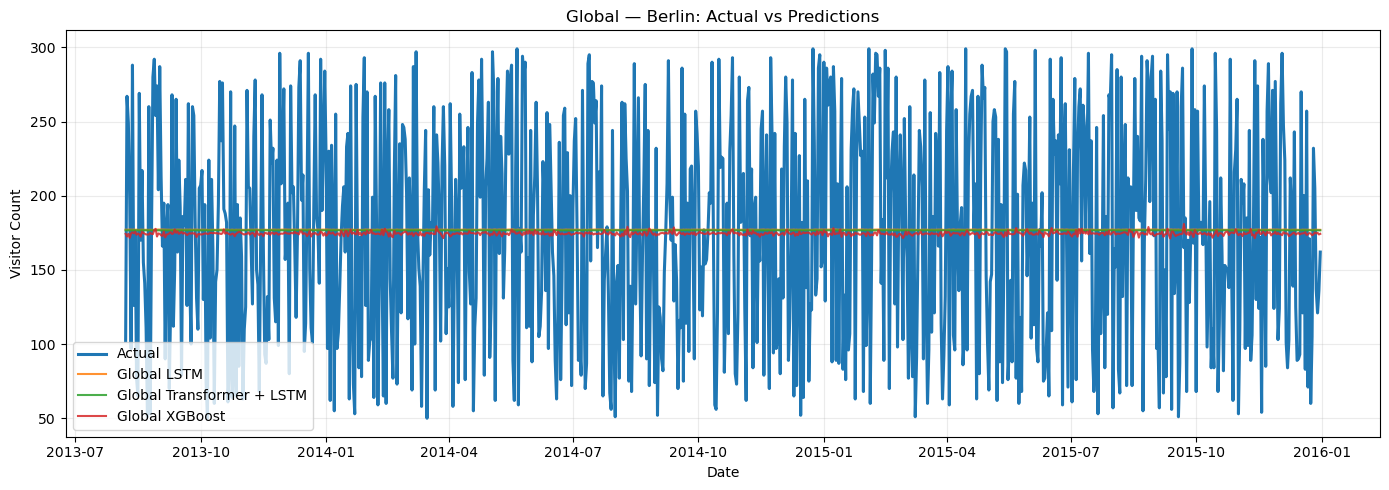

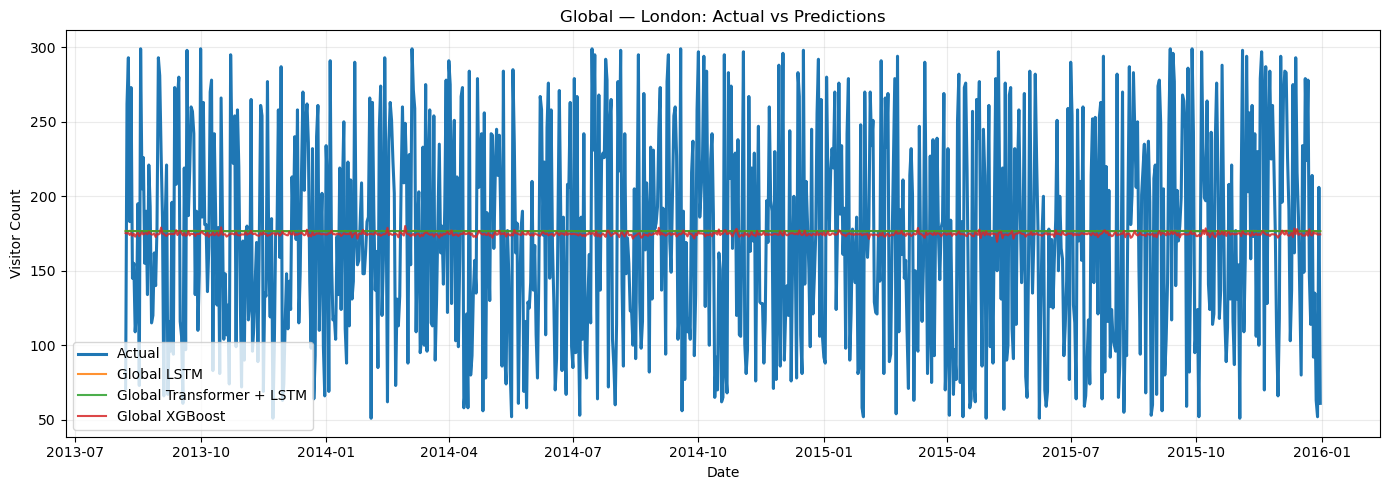

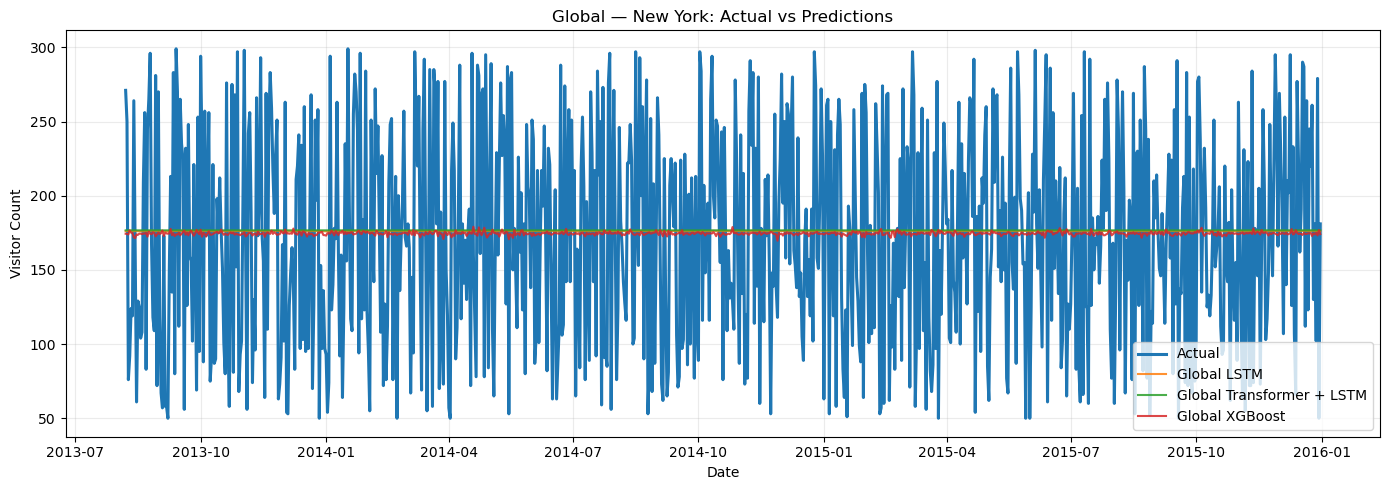

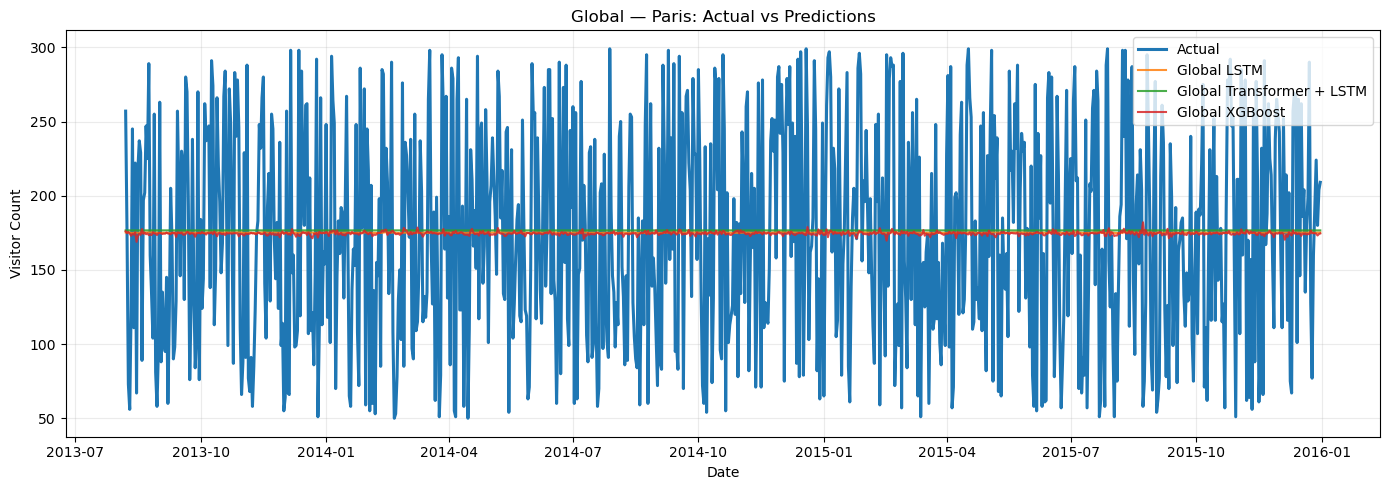

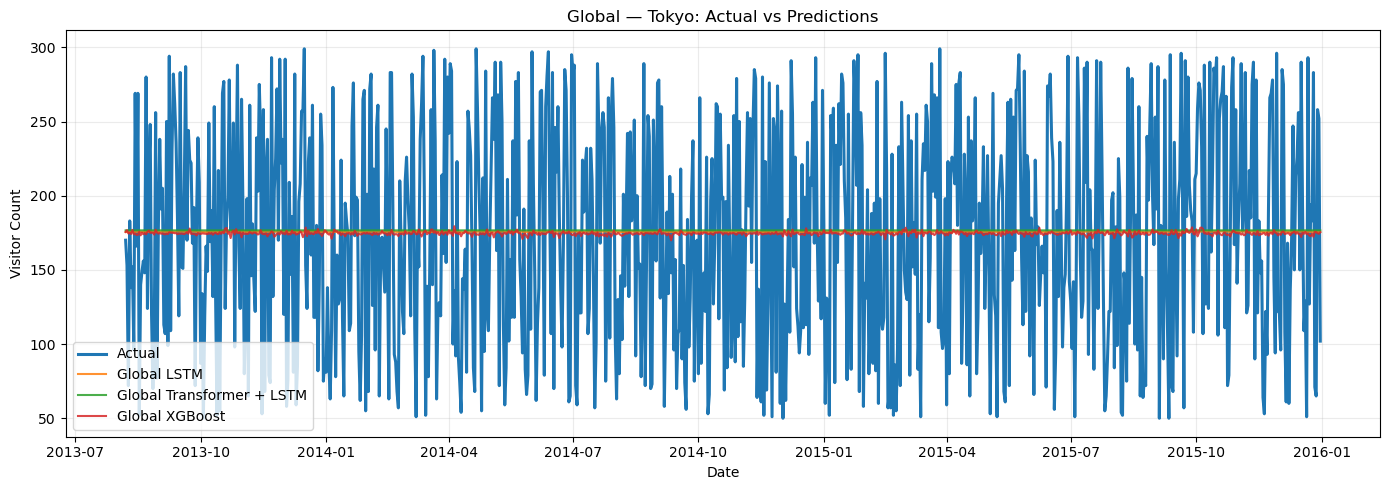

In [9]:
for scope in ["Single", "Global"]:
    scope_data = pred_all[pred_all["Scope"] == scope]
    for city in sorted(scope_data["Destination"].unique()):
        city_data = scope_data[scope_data["Destination"] == city]
        plt.figure(figsize=(14, 5))
        actual_ref = city_data[["Date", "Actual"]].drop_duplicates("Date").sort_values("Date")
        plt.plot(actual_ref["Date"], actual_ref["Actual"], label="Actual", linewidth=2.2)
        for model, g in city_data.groupby("Model"):
            g = g.sort_values("Date")
            plt.plot(g["Date"], g["Predicted"], label=model, alpha=.85)
        plt.title(f"{scope} — {city}: Actual vs Predictions")
        plt.xlabel("Date")
        plt.ylabel("Visitor Count")
        plt.legend()
        plt.grid(alpha=.25)
        plt.tight_layout()
        plt.show()

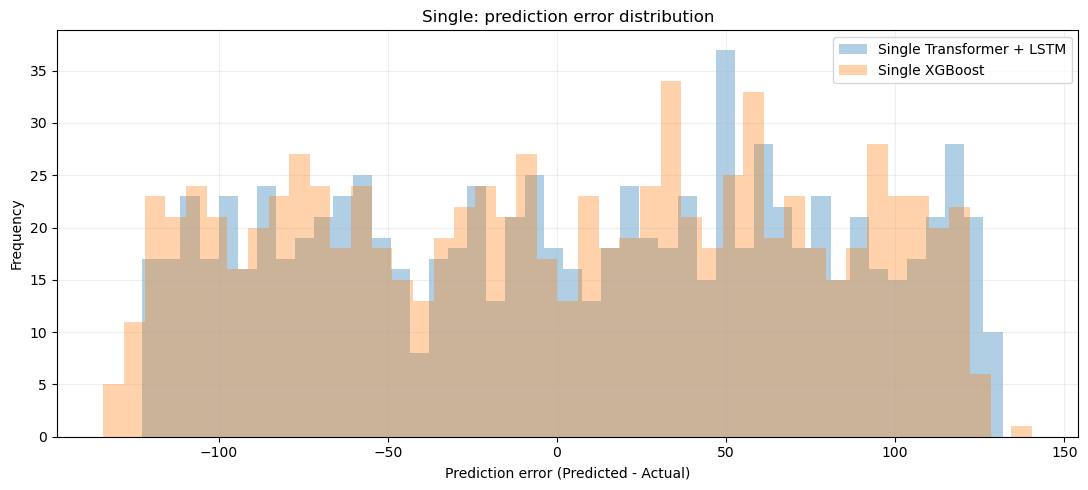

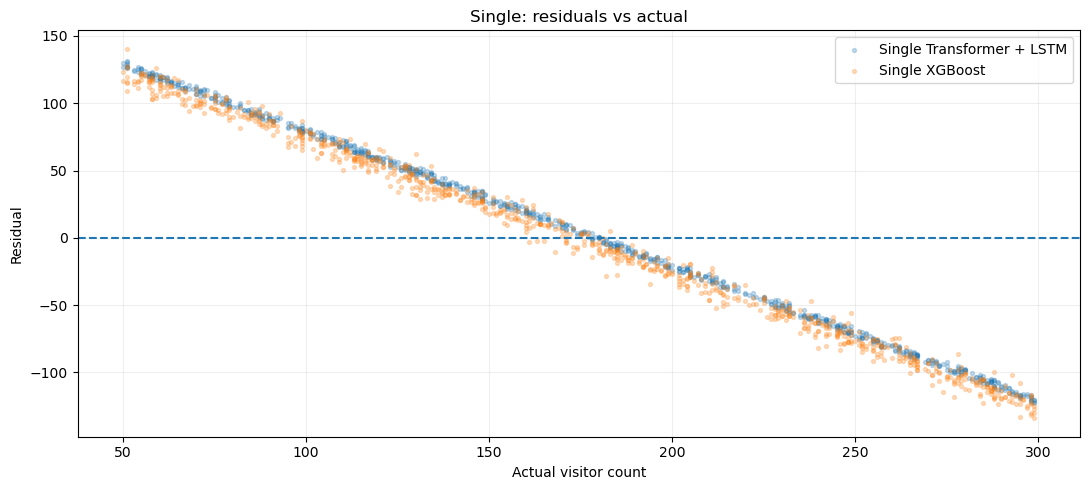

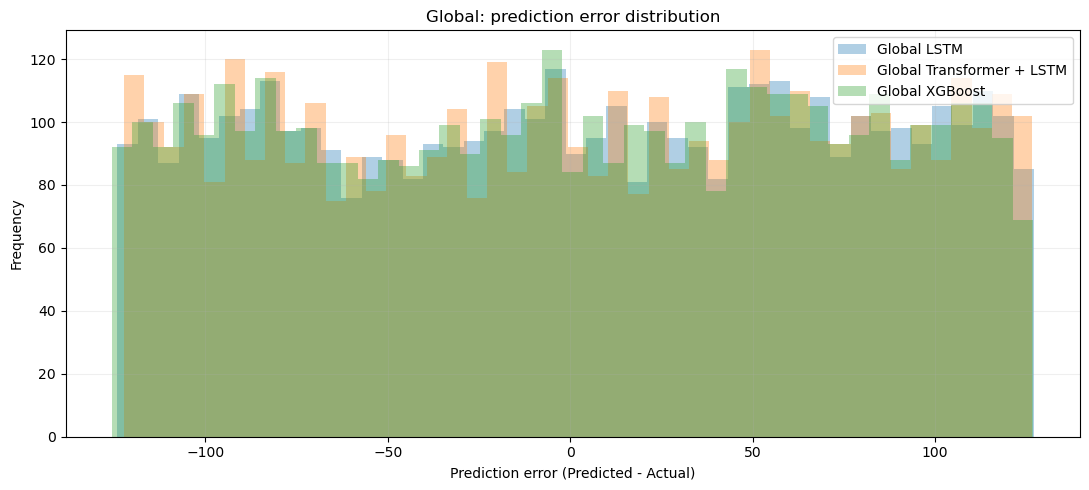

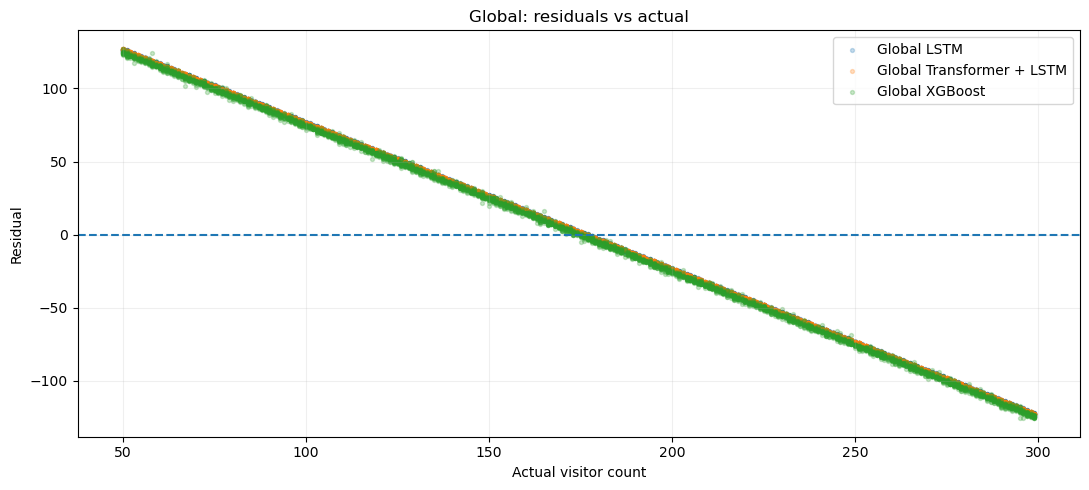

In [10]:
for scope in ["Single", "Global"]:
    scope_data = pred_all[pred_all["Scope"] == scope].copy()
    if scope_data.empty:
        continue
    scope_data["Error"] = scope_data["Predicted"] - scope_data["Actual"]
    plt.figure(figsize=(11, 5))
    for model, g in scope_data.groupby("Model"):
        plt.hist(g["Error"], bins=45, alpha=.35, label=model)
    plt.title(f"{scope}: prediction error distribution")
    plt.xlabel("Prediction error (Predicted - Actual)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(11, 5))
    for model, g in scope_data.groupby("Model"):
        plt.scatter(g["Actual"], g["Predicted"]-g["Actual"], s=8, alpha=.25, label=model)
    plt.axhline(0, linestyle="--")
    plt.title(f"{scope}: residuals vs actual")
    plt.xlabel("Actual visitor count")
    plt.ylabel("Residual")
    plt.legend()
    plt.grid(alpha=.2)
    plt.tight_layout()
    plt.show()

In [11]:
# ZIP ปัจจุบันไม่มี history CSV/JSON ที่บันทึก loss ราย epoch
# ถ้าภายหลังบันทึก history เป็น CSV ให้ใส่ path ในรายการนี้
history_files = {
    # "Single LSTM": "path/to/single_lstm_history.csv",
    # "Single Transformer + LSTM": "path/to/single_transformer_history.csv",
    # "Global LSTM": "path/to/global_lstm_history.csv",
    # "Global Transformer + LSTM": "path/to/global_transformer_history.csv",
}

for model_name, rel_path in history_files.items():
    p = ROOT / rel_path
    if not p.exists():
        print("Missing history:", p)
        continue
    h = pd.read_csv(p)
    train_col = next((c for c in ["train_loss", "Train Loss", "train"] if c in h.columns), None)
    val_col = next((c for c in ["val_loss", "Validation Loss", "val"] if c in h.columns), None)
    if train_col and val_col:
        plt.figure(figsize=(9, 4))
        plt.plot(h[train_col], label="Train Loss")
        plt.plot(h[val_col], label="Validation Loss")
        plt.title(model_name + " — Loss history")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.legend()
        plt.grid(alpha=.25)
        plt.show()
    else:
        print("ไม่พบคอลัมน์ train/validation loss ใน", rel_path)

print("หมายเหตุ: Loss เดิมของแต่ละโมเดลอาจอยู่บน scaled target และไม่ควรนำไปเทียบข้ามโมเดลโดยตรง หาก preprocessing ต่างกัน")

หมายเหตุ: Loss เดิมของแต่ละโมเดลอาจอยู่บน scaled target และไม่ควรนำไปเทียบข้ามโมเดลโดยตรง หาก preprocessing ต่างกัน


In [12]:
single_lstm_metrics_path = ROOT / "outputs/test_metrics.csv"
if single_lstm_metrics_path.exists():
    old = pd.read_csv(single_lstm_metrics_path)
    display(old)
    print("Single LSTM มี metrics เดิม แต่ไม่มี predictions CSV ใน ZIP")
else:
    print("ไม่พบ outputs/test_metrics.csv")

,Metric,Value
0,MAE,63.569626
1,RMSE,73.006083
2,sMAPE (%),38.963902


Single LSTM มี metrics เดิม แต่ไม่มี predictions CSV ใน ZIP


In [13]:
OUT = ROOT / "model_comparison_report"
OUT.mkdir(exist_ok=True)

metrics_df.to_csv(OUT / "model_metrics_by_city.csv", index=False)
baseline_df.to_csv(OUT / "baseline_metrics_by_city.csv", index=False)
comparison_df.to_csv(OUT / "model_and_baseline_comparison.csv", index=False)
inventory_df.to_csv(OUT / "model_file_inventory.csv", index=False)

if not pred_all.empty:
    pred_all.to_csv(OUT / "all_model_predictions.csv", index=False)

print("Saved report tables to:", OUT.resolve())

Saved report tables to: D:\Coding\thesis\model_comparison_report
